# 4 · Aprender un mundo para planificar dentro de él

**Lectura acompañada:** §§4.1–4.5, pp. 83–120 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Necesitas Bellman y distinguir interacción real de cálculo.

**Objetivo:** experimentar con planificación al decidir, planificación durante el entrenamiento y representaciones predictivas. Implementaremos un controlador lineal, Dyna-Q y una representación sucesora. Son modelos pequeños para entender mecanismos, no reproducciones de Dreamer o MuZero.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})


## 1. §4.1 · Comprar datos o hacer más cálculos

Si cada intento de un robot cuesta tiempo, energía o desgaste, un modelo aprendido puede permitir ensayar alternativas sin ejecutarlas. La ganancia potencial es eficiencia en interacciones; el coste es cómputo y error de modelo.

Un modelo de un paso predice transiciones y recompensas. Componerlo muchas veces genera trayectorias imaginadas. Pero pequeñas discrepancias pueden acumularse, y la política puede encontrar acciones que exploten precisamente donde el modelo se equivoca.

Separamos tres usos: planificar con un modelo conocido, aprender ese modelo y mejorar una política usando sus predicciones. Pueden combinarse, pero una demostración que usa dinámica exacta no prueba que sepamos aprenderla desde imágenes.

Para verlo, considera un estado real constante y un modelo que lo multiplica por 1.05 en cada paso. Una desviación local del 5% no sigue siendo pequeña indefinidamente.


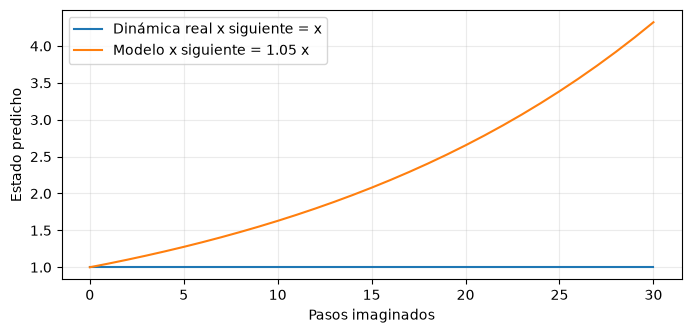

Error en un paso: 0.050000000000000044 Error en treinta: 3.321942375150668


In [2]:
horizontes = np.arange(31)
real = np.ones_like(horizontes, dtype=float)
predicho = 1.05**horizontes
plt.plot(horizontes, real, label="Dinámica real x siguiente = x")
plt.plot(horizontes, predicho, label="Modelo x siguiente = 1.05 x")
plt.xlabel("Pasos imaginados")
plt.ylabel("Estado predicho")
plt.legend()
plt.show()
print("Error en un paso:", predicho[1]-1, "Error en treinta:", predicho[-1]-1)


No todo error crece exponencialmente: sistemas contractivos pueden amortiguarlo. Lo que importa es la combinación de error local, dinámica, horizonte y estados visitados por la política.

## 2. §4.2 · Planificar ahora y volver a mirar después

Una secuencia de acciones es un plan de lazo abierto. Una política puede reaccionar a futuras observaciones. MPC optimiza una secuencia, ejecuta solo su primera acción, observa de nuevo y repite. El optimizador interno trabaja con secuencias; el controlador completo sí utiliza realimentación.

Vamos a controlar $x_{t+1}=a x_t+u_t$ y minimizar

$$\sum_{t=0}^{H-1}(x_t^2+0.1u_t^2)+x_H^2.$$

No imponemos límites a las acciones. En este sistema lineal con coste cuadrático, la recursión de Riccati da el plan óptimo para el modelo. Así evitamos atribuir al azar del optimizador diferencias que queremos relacionar con replanificar.


In [3]:
def plan_lineal(x0, horizonte, a=0.95, penalizacion=0.1):
    P = 1.0  # Coste terminal x_H^2.
    ganancias = []
    for _ in range(horizonte):
        K = a * P / (penalizacion + P)
        ganancias.append(K)
        P = 1 + a*a*P - (a*P)**2 / (penalizacion + P)
    x = float(x0)
    acciones = []
    for K in reversed(ganancias):
        u = -K*x
        acciones.append(u)
        x = a*x + u
    return np.array(acciones)

plan = plan_lineal(3.0, 20)
print("Primeras acciones del plan:", plan[:5])
assert abs(0.95*3 + plan[0]) < 3


Primeras acciones del plan: [-2.609  -0.2096 -0.0168 -0.0014 -0.0001]


## 3. Un golpe inesperado revela la diferencia

Usaremos exactamente la misma perturbación exógena para ambos controladores. Un plan se calcula al inicio y no se modifica. El otro vuelve a resolver un horizonte de ocho pasos en cada instante. Ninguno conoce el golpe futuro.

La comparación cambia tanto la realimentación como la cantidad de planificación. Por eso no interpretaremos el resultado como una comparación a igual cómputo.


Plan inicial fijo coste: 39.958
MPC: replanifica coste: 14.074


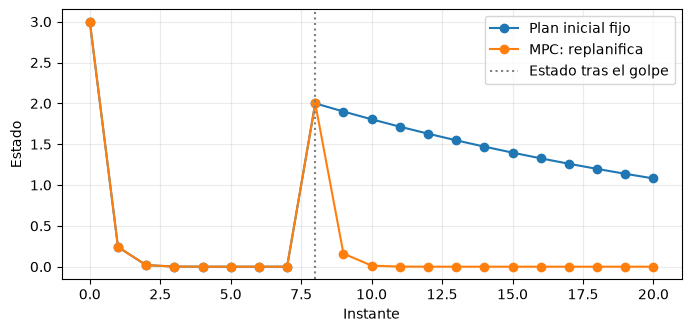

In [4]:
def controlar(replanificar, perturbaciones, a_real=0.95, a_modelo=0.95):
    x = 3.0
    trayectoria = [x]
    acciones = []
    plan_inicial = plan_lineal(x, len(perturbaciones), a_modelo)
    for t, ruido in enumerate(perturbaciones):
        u = plan_lineal(x, 8, a_modelo)[0] if replanificar else plan_inicial[t]
        acciones.append(u)
        x = a_real*x + u + ruido
        trayectoria.append(x)
    estados = np.array(trayectoria)
    acciones = np.array(acciones)
    coste = np.sum(estados[:-1]**2 + 0.1*acciones**2) + estados[-1]**2
    return estados, acciones, coste

perturbaciones = np.zeros(20)
perturbaciones[7] = 2.0
for replanificar in [False, True]:
    estados, acciones, coste = controlar(replanificar, perturbaciones)
    nombre = "MPC: replanifica" if replanificar else "Plan inicial fijo"
    plt.plot(estados, "o-", label=nombre)
    print(nombre, "coste:", round(coste, 3))
plt.axvline(8, color="gray", linestyle=":", label="Estado tras el golpe")
plt.xlabel("Instante")
plt.ylabel("Estado")
plt.legend()
plt.show()


Al observar el salto, MPC puede corregirlo. Esto no convierte a MPC en una solución óptima universal del problema estocástico: una política que anticipase el valor de futuras observaciones podría decidir de otra forma.

En problemas no lineales, random shooting evalúa secuencias muestreadas; CEM concentra el muestreo en candidatas prometedoras; MPPI pondera perturbaciones de controles. Branch and bound y búsqueda heurística intentan evitar explorar todo un árbol. Elegir una técnica depende de dinámica, restricciones y coste de evaluación.

## 4. Buscar selectivamente: la intuición de MCTS

MCTS distribuye simulaciones entre ramas del árbol. Una idea habitual equilibra valor estimado y una bonificación por pocas visitas. En una forma simple:

$$\operatorname{score}(a)=\bar Q(a)+c\sqrt{\frac{\log N}{N(a)}}.$$

Las acciones no visitadas necesitan tratamiento especial. El código siguiente es solo la selección en un nodo ya visitado, no un MCTS completo.


In [5]:
valores = np.array([0.6, 0.55, 0.3])
visitas = np.array([100, 10, 2])
for c in [0.0, 0.5, 1.0]:
    scores = valores + c*np.sqrt(np.log(visitas.sum())/visitas)
    print(f"c={c}: scores={scores}, rama elegida={scores.argmax()}")


c=0.0: scores=[0.6  0.55 0.3 ], rama elegida=0
c=0.5: scores=[0.7086 0.8935 1.068 ], rama elegida=2
c=1.0: scores=[0.8172 1.2369 1.836 ], rama elegida=2


AlphaZero planifica con reglas conocidas y redes que aportan políticas y valores. MuZero aprende una dinámica latente orientada a las cantidades necesarias para decidir. No necesita reconstruir perfectamente cada píxel para que esa representación resulte útil; sí necesita preservar información relevante para la tarea.

## 5. §4.3 · Dyna: usar el modelo antes de la siguiente decisión

Dyna desplaza parte de la planificación al entrenamiento. Cada transición real actualiza Q y un modelo; después se muestrean transiciones del modelo para realizar más actualizaciones. La política desplegada puede ser una consulta rápida de Q.

En nuestra cadena determinista, el modelo es un diccionario de transiciones ya observadas. No conoce estados nunca visitados. Repetir actualizaciones propaga más rápido la información disponible; no inventa información sobre transiciones desconocidas.

Primero escribimos una única actualización que servirá para datos reales e imaginados. El indicador terminal evita acumular valor después del final.


In [6]:
def backup(Q, s, a, siguiente, premio, terminal, alpha=0.2, gamma=0.95):
    objetivo = premio + gamma*(not terminal)*Q[siguiente].max()
    Q[s, a] += alpha*(objetivo-Q[s, a])

def q_optima_cadena(n=9, gamma=0.95):
    Q = np.zeros((n, 2))
    for _ in range(2*n):
        anterior = Q.copy()
        for s in range(1, n-1):
            for a in range(2):
                ns = s + (1 if a else -1)
                Q[s, a] = float(ns == n-1) + gamma*(ns not in (0, n-1))*anterior[ns].max()
    return Q

Q_opt = q_optima_cadena()
print("Q óptimo desde el primer estado interior:", Q_opt[1])


Q óptimo desde el primer estado interior: [0.     0.7351]


El bucle registra Q cada veinte transiciones. Separa generadores de acciones y planificación: el consumo de números aleatorios del planificador no altera directamente el generador de exploración, aunque las políticas sí cambian y con ellas las trayectorias.


Planificación: 0 Backups por réplica: 1200 RMSE final: 0.05837716593723806


Planificación: 5 Backups por réplica: 7200 RMSE final: 9.619390824908338e-16


Planificación: 20 Backups por réplica: 25200 RMSE final: 9.619390824908338e-16


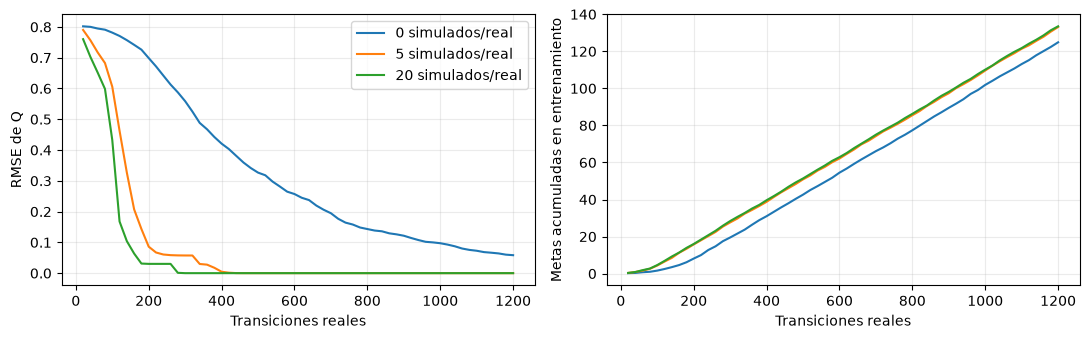

In [7]:
def dyna(seed, planificacion, pasos=1200, n=9):
    rng = np.random.default_rng(seed)
    rng_plan = np.random.default_rng(seed + 100000)
    Q = np.zeros((n, 2))
    modelo, claves = {}, []
    registros, metas = [], []
    s, exitos = 1, 0
    for t in range(1, pasos+1):
        mejores = np.flatnonzero(np.isclose(Q[s], Q[s].max(), atol=1e-12, rtol=0))
        a = int(rng.integers(2) if rng.random() < 0.2 else rng.choice(mejores))
        ns = s + (1 if a else -1)
        r, terminal = float(ns == n-1), ns in (0, n-1)
        backup(Q, s, a, ns, r, terminal)
        if (s, a) not in modelo:
            claves.append((s, a))
        modelo[s, a] = (ns, r, terminal)
        for _ in range(planificacion):
            sm, am = claves[int(rng_plan.integers(len(claves)))]
            backup(Q, sm, am, *modelo[sm, am])
        exitos += ns == n-1
        s = 1 if terminal else ns
        if t % 20 == 0:
            registros.append(Q.copy())
            metas.append(exitos)
    return np.array(registros), np.array(metas)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for planificacion in [0, 5, 20]:
    datos = [dyna(SEMILLA+k, planificacion) for k in range(8)]
    tablas = np.array([d[0] for d in datos])
    metas = np.array([d[1] for d in datos])
    error = np.sqrt(((tablas[:, :, 1:-1]-Q_opt[None, None, 1:-1])**2).mean(axis=(2, 3)))
    x = np.arange(1, error.shape[1]+1)*20
    axes[0].plot(x, error.mean(axis=0), label=f"{planificacion} simulados/real")
    axes[1].plot(x, metas.mean(axis=0), label=f"{planificacion} simulados/real")
    print("Planificación:", planificacion, "Backups por réplica:", 1200*(1+planificacion),
          "RMSE final:", error[:, -1].mean())
axes[0].set(xlabel="Transiciones reales", ylabel="RMSE de Q")
axes[1].set(xlabel="Transiciones reales", ylabel="Metas acumuladas en entrenamiento")
axes[0].legend()
plt.tight_layout()
plt.show()


Más planificación puede aprovechar mejor las mismas interacciones, pero hace más backups. Las metas acumuladas describen rendimiento mientras se aprende, no una evaluación independiente de la política final. En esta tabla determinista no hay error de modelo para las transiciones almacenadas; con dinámica estocástica no bastaría guardar solo la última observación como si fuese la verdad.

## 6. §4.4 · Qué debería aprender un modelo del mundo

Reconstruir observaciones ofrece muchas señales de entrenamiento, pero puede dedicar capacidad a detalles irrelevantes. Predecir recompensa, valor o representaciones futuras centra la capacidad en decidir, a costa de depender más del objetivo y de la cobertura de datos.

Dreamer aprende dinámica latente y entrena comportamientos en imaginación. IRIS utiliza representaciones discretas y modelos autorregresivos. TD-MPC combina representaciones orientadas a tarea y control predictivo. Las variantes inspiradas en autopredicción, como BYOL o JEPA, deben evitar el colapso: representar todo por el mismo vector haría fácil predecir y eliminaría información útil.

Rollouts cortos, conjuntos de modelos e incertidumbre pueden reducir el impacto de errores acumulados. Ninguno garantiza reconocer todos los fallos fuera de distribución. Conviene medir error en los estados que visita la política mejorada, no solo en un conjunto estático fácil.


## 7. §4.5 · Predecir ocupación futura en vez de un solo paso

Una representación sucesora de una política fija resume visitas descontadas:

$$M^\pi=(I-\gamma P^\pi)^{-1},\qquad V^\pi=M^\pi r.$$

Cada fila indica cuánto esperamos ocupar cada estado desde un inicio. Si cambia la recompensa por estado, podemos recalcular valores sin reconstruir todas las transiciones futuras. La condición «política fija» es esencial: cambiar la recompensa puede hacer que otra política sea mejor.

El capítulo amplía esta idea a successor features y representaciones predictivas. Separar dinámica o ocupación de recompensa puede facilitar transferencia, siempre que la representación conserve las cantidades necesarias para la nueva tarea.


In [8]:
P_pi = np.array([[0.0, 1.0, 0.0],
                 [0.0, 0.5, 0.5],
                 [0.0, 0.0, 1.0]])
gamma = 0.9
M = np.linalg.solve(np.eye(3)-gamma*P_pi, np.eye(3))
print("Ocupaciones descontadas:\n", M)
for recompensas in [np.array([0, 1, 0]), np.array([0, -1, 0])]:
    V = M @ recompensas
    np.testing.assert_allclose(V, recompensas + gamma*P_pi@V)
    print("Recompensa por estado:", recompensas, "Valor de la misma política:", V)


Ocupaciones descontadas:
 [[ 1.      1.6364  7.3636]
 [ 0.      1.8182  8.1818]
 [ 0.      0.     10.    ]]
Recompensa por estado: [0 1 0] Valor de la misma política: [1.6364 1.8182 0.    ]
Recompensa por estado: [ 0 -1  0] Valor de la misma política: [-1.6364 -1.8182  0.    ]


El estado absorbente tiene ocupación descontada positiva, aunque su recompensa sea cero. No confundas número de visitas esperado con probabilidad de visitar alguna vez: la primera puede superar uno.

## 8. Ejercicio: modelo incorrecto y horizonte

Cambia la dinámica real y conserva el modelo del controlador. Predice si observar y corregir será suficiente en esta tarea. Después repite el experimento de Dyna con cero planificación y describe qué parte del procedimiento desaparece.


In [9]:
for a_real in [0.8, 0.95, 1.1]:
    fila = []
    for replanificar in [False, True]:
        _, _, coste = controlar(replanificar, perturbaciones, a_real=a_real, a_modelo=0.95)
        fila.append(coste)
    print(f"a real={a_real}: coste plan fijo={fila[0]:.3f}, coste MPC={fila[1]:.3f}")


a real=0.8: coste plan fijo=20.070, coste MPC=14.051
a real=0.95: coste plan fijo=39.958, coste MPC=14.074
a real=1.1: coste plan fijo=464.316, coste MPC=14.767


<details>
<summary>Solución orientativa</summary>

MPC usa el nuevo estado para corregir predicciones, por lo que puede tolerar cierto error de modelo. Eso no constituye una garantía de estabilidad con cualquier error, restricción o horizonte. El sistema lineal de una dimensión es deliberadamente sencillo.

Con cero planificación, Dyna conserva la actualización sobre experiencia real y ya no utiliza las transiciones almacenadas para mejorar Q. El diccionario deja de aportar aprendizaje; el procedimiento se reduce al núcleo de Q-learning del ejemplo.

</details>

Para el grupo: compara coste de interacción, coste de cómputo, error de modelo y tiempo de decisión de cada método. La siguiente lección añadirá otros agentes que cambian sus políticas, haciendo menos estable aquello que intentamos modelar.

**Fuente:** adaptación de [Murphy, capítulo 4](https://arxiv.org/html/2412.05265v5#Ch4), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). [Resumen y ejecución de referencia](../docs/04_modelos.md). Ejemplos y código propios.
